# Hyperbolic Graph Neural Networks

This notebook is part of the lab semiar [Machine Learning and AI in the Life Sciences: Methods and Applications](https://www.fu-berlin.de/vv/de/lv/935203) at Freie Universität Berlin.

In this practical we will implement a hyperbolic graph convolutional network. As last week we will apply it to the problem of graph-level prediction of the properties of drug-like molecules.

## Setup environment

Let's install the required python packages. We will be working with the [`jax` library](https://docs.jax.dev/en/latest/index.html) and its ecosystem of deep learning tools. For hyperbolic space we use the [`Morphomatics` library](https://morphomatics.github.io/)

In [ ]:
%%capture
!pip install ipdb
!pip install jax jraph flax optax torch-geometric
!pip install morphomatics

# QM9 Dataset

We will work with the QM9 dataset that is a benchmark database used in machine learning for molecular properties. It contains data for 133k small organic molecules with 19 regression targets. We can use the PyG libraray to load the molecules as graphs equpped with a number of pre-computed features:

**Atom features (`G.x`)** - $\mathbb{R}^{|V| \times 11}$
- 1st-5th features: Atom type (one-hot: H, C, N, O, F)
- 6th feature (also `data.z`): Atomic number (number of protons).
- 7th feature: Aromatic (binary)
- 8th-10th features: Electron orbital hybridization (one-hot: sp, sp2, sp3)
- 11th feature: Number of hydrogens

**Edge Index (`G.edge_index`)** - $\mathbb{R}^{2×|E|}$
- A tensor of dimensions 2 x `G.num_edges` that describe the edge connectivity of the graph

**Edge features (`G.edge_attr`)** - $\mathbb{R}^{|E|\times 4}$
- 1st-4th features: bond type (one-hot: single, double, triple, aromatic)

**Atom positions (`G.pos`)** - $\mathbb{R}^{|V|\times 3}$
- 3D coordinates of each atom.

**Target (`G.y`)** - $\mathbb{R}^{19}$

| Target | Property                      | Unit         | Description                                              |
|--------|-------------------------------|--------------|----------------------------------------------------------|
| 0      | $\mu$                         | D            | Dipole moment                                            |
| 1      | $\alpha$                      | $a_0^3$      | Isotropic polarizability                                |
| 2      | $\epsilon_{\textrm{HOMO}}$    | eV           | Highest occupied molecular orbital energy                |
| 3      | $\epsilon_{\textrm{LUMO}}$    | eV           | Lowest unoccupied molecular orbital energy               |
| 4      | $\Delta \epsilon$             | eV           | Gap between $\epsilon_{\textrm{HOMO}}$ and $\epsilon_{\textrm{LUMO}}$ |
| 5      | $\langle R^2 \rangle$         | $a_0^2$      | Electronic spatial extent                                |
| 6      | ZPVE                          | eV           | Zero point vibrational energy                            |
| 7      | $U_0$                         | eV           | Internal energy at 0K                                    |
| 8      | $U$                           | eV           | Internal energy at 298.15K                               |
| 9      | $H$                           | eV           | Enthalpy at 298.15K                                      |
| 10     | $G$                           | eV           | Free energy at 298.15K                                   |
| 11     | $c_{\textrm{v}}$              | cal/mol·K    | Heat capacity at 298.15K                                 |
| 12     | $U_0^{\textrm{ATOM}}$         | eV           | Atomization energy at 0K                                 |
| 13     | $U^{\textrm{ATOM}}$           | eV           | Atomization energy at 298.15K                            |
| 14     | $H^{\textrm{ATOM}}$           | eV           | Atomization enthalpy at 298.15K                          |
| 15     | $G^{\textrm{ATOM}}$           | eV           | Atomization free energy at 298.15K                       |
| 16     | $A$                           | GHz          | Rotational constant                                      |
| 17     | $B$                           | GHz          | Rotational constant                                      |
| 18     | $C$                           | GHz          | Rotational constant                                      |



In [ ]:
from typing import NamedTuple

import torch
from torch_geometric.datasets import QM9
import torch_geometric.transforms as T
from torch_geometric.utils import remove_self_loops

import numpy as np
import jax
import jax.numpy as jnp
class SetTarget(NamedTuple):
    target: int = 0
    """
    Only keep the label for a specific target (there are 19 targets in QM9).
    """
    def __call__(self, data):
        data.y = data.y[:, self.target]
        return data

# Transforms which are applied during data loading:
transform = SetTarget(0)

# Define our dataset, using torch datasets
qm9_dataset = QM9('./qm9/', transform=transform)
print(f"Total number of samples: {len(qm9_dataset)}.")

# Split datasets (subset of full dataset for efficiency)
train_dataset = qm9_dataset[:1000]
val_dataset = qm9_dataset[1000:2000]
test_dataset = qm9_dataset[2000:3000]
print(f"Created dataset splits with {len(train_dataset)} training, {len(val_dataset)} validation, {len(test_dataset)} test samples.")


Extracting qm9/raw/qm9_v3.zip
Processing...
Using a pre-processed version of the dataset. Please install 'rdkit' to alternatively process the raw data.
Done!


Total number of samples: 130831.
Created dataset splits with 1000 training, 1000 validation, 1000 test samples.


In [ ]:
import torch_geometric
from typing import List, Generator
from torch.utils.data import DataLoader, default_collate

import jraph

MAX_NUM_NODES = 29
MAX_NUM_EDGES = 56
TYPE = jnp.float32

def jraph_iterate(data: List[torch_geometric.data.Data]) -> Generator[jraph.GraphsTuple, None, None]:
    for G in data:
        yield jraph.GraphsTuple(
            n_node=jnp.asarray([G.num_nodes]),
            n_edge=jnp.asarray([G.num_edges]),
            nodes=jnp.asarray(G.x, dtype=TYPE),
            edges=jnp.ones(G.num_edges, dtype=TYPE),
            globals=jnp.asarray([G.y], dtype=TYPE),
            senders=jnp.asarray(G.edge_index[0]),
            receivers=jnp.asarray(G.edge_index[1]))

def jraph_collate(batch: List[torch_geometric.data.Data]) -> Generator[jraph.GraphsTuple, None, None]:
  """
  Collate function specifies how to combine a list of data samples into a batch.
  default_collate creates pytorch tensors, then tree_map converts them into numpy arrays.
  """
  batch_size = len(batch)
  return next(jraph.dynamically_batch(
        jraph_iterate(batch),
        n_node=batch_size * MAX_NUM_NODES + 1, # Plus one for the extra padding node.
        n_edge=batch_size * MAX_NUM_EDGES,
        n_graph=batch_size + 1))


training_generator = DataLoader(qm9_dataset, batch_size=5, collate_fn=jraph_collate)

# Create pytorch data loader with custom collate function
train_loader = DataLoader(train_dataset, batch_size=32, collate_fn=jraph_collate, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=32, collate_fn=jraph_collate, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=32, collate_fn=jraph_collate, shuffle=False)

# Hyperbolic embedding

> <img src="https://cdn-icons-png.freepik.com/256/8089/8089604.png?semt=ais_hybrid" alt="drawing" width="100"/> <br>
> * implement a function that embedds a QM9 graph `G` into the Lorentz model of hyperbolic space (i.e. assign a hyperbolic target to each node based on its features `G.x`)
> * visualize the embedding for an example graph embedded into hyperbolic 2-space

**TIP:** Note that the definitions in [Liu et al. 2019] and the implementation in `Morphomatics` differ in the choice of symmetry axis of the hyperboloid, i.e. $(1, 0, ..., 0)$ versus $(0, ..., 0, 1)$, respectively.

In [ ]:
from morphomatics.manifold import HyperbolicSpace


def embedd(G: jraph.GraphsTuple, d: int) -> jraph.GraphsTuple:
  #features to embed and init. hyp. space
    x = G.nodes[:, :d]  # nodes x features
    H = HyperbolicSpace((d+1,))
    origin = H.pole()
    origin_batch = jnp.broadcast_to(origin, (x.shape[0], d+1))

    #creating tangent vecs
    zeros_col = jnp.zeros((x.shape[0], 1))
    tangent_vecs = jnp.concatenate([ x,zeros_col], axis=1)

    #map
    nodes_embedded = jax.vmap(H._metric.exp)(origin_batch, tangent_vecs)
    return G._replace(nodes=nodes_embedded)

Original node features:
[[0. 1. 0. 0. 0. 6. 0. 0. 0. 0. 3.]
 [0. 1. 0. 0. 0. 6. 0. 0. 0. 0. 1.]
 [0. 1. 0. 0. 0. 6. 0. 0. 0. 0. 2.]
 [0. 1. 0. 0. 0. 6. 0. 0. 0. 0. 2.]
 [1. 0. 0. 0. 0. 1. 0. 0. 0. 0. 0.]
 [1. 0. 0. 0. 0. 1. 0. 0. 0. 0. 0.]
 [1. 0. 0. 0. 0. 1. 0. 0. 0. 0. 0.]
 [1. 0. 0. 0. 0. 1. 0. 0. 0. 0. 0.]
 [1. 0. 0. 0. 0. 1. 0. 0. 0. 0. 0.]
 [1. 0. 0. 0. 0. 1. 0. 0. 0. 0. 0.]
 [1. 0. 0. 0. 0. 1. 0. 0. 0. 0. 0.]
 [1. 0. 0. 0. 0. 1. 0. 0. 0. 0. 0.]]
Size of embedded graph: (12, 12)
Embedded graph:(after PCA):
[[ 4.7032181e+02  4.1518764e+01  8.4683490e-01]
 [ 1.8023015e+02 -4.5562847e+01  1.4289451e+00]
 [ 2.7425864e+02 -1.2624593e+01 -1.1752564e+00]
 [ 2.7425864e+02 -1.2624593e+01 -1.1752565e+00]
 [-1.4988367e+02  3.6616566e+00  9.3200170e-03]
 [-1.4988367e+02  3.6616566e+00  9.3200170e-03]
 [-1.4988367e+02  3.6616566e+00  9.3200170e-03]
 [-1.4988367e+02  3.6616566e+00  9.3200170e-03]
 [-1.4988367e+02  3.6616566e+00  9.3200170e-03]
 [-1.4988367e+02  3.6616566e+00  9.3200170e-03]
 [

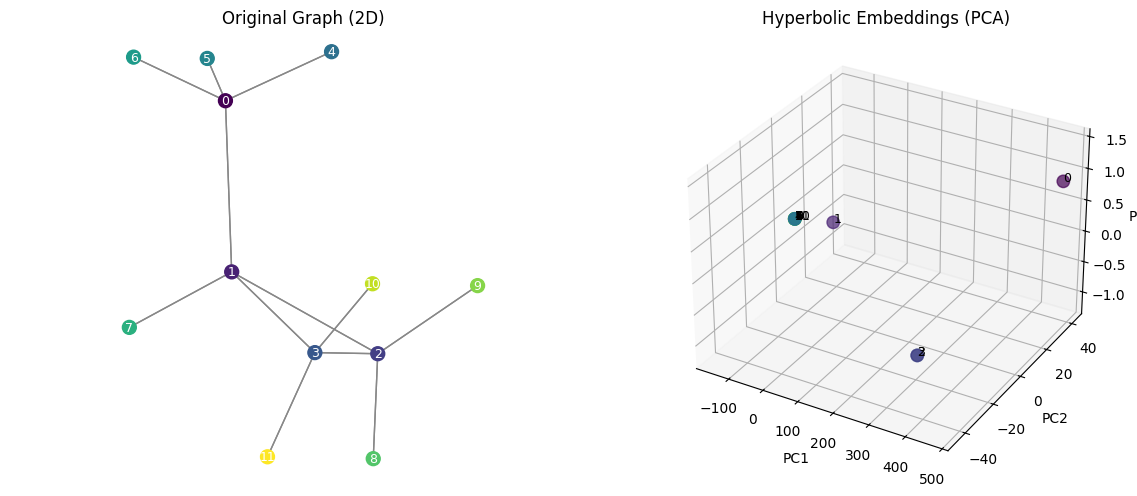

In [ ]:
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

example = train_dataset[42]
example_jraph = next(jraph_iterate([example]))

print("Original node features:")
print(example_jraph.nodes)

embedded_graph = embedd(example_jraph, 11)
embedded_nodes = np.array(embedded_graph.nodes)
print("Size of embedded graph:",embedded_nodes.shape)
# PCA
pca = PCA(n_components=3)
nodes_pca = pca.fit_transform(embedded_nodes)

print("Embedded graph:(after PCA):")
print(nodes_pca)
print("Shape:", nodes_pca.shape)
#plot
colors = np.arange(nodes_pca.shape[0])


fig = plt.figure(figsize=(12, 5))

#org graph
ax1 = fig.add_subplot(1, 2, 1)

node_xy = example['pos'][:, :2]

#nod
ax1.scatter(node_xy[:, 0], node_xy[:, 1], c=colors, s=100, cmap='viridis', zorder=2)
for i, (x, y) in enumerate(node_xy):
    ax1.text(x, y, str(i), fontsize=9, ha='center', va='center', color='white', zorder=3)

#edges
edges = example['edge_index'].T
for src, tgt in edges:
    ax1.plot(
        [node_xy[src, 0], node_xy[tgt, 0]],
        [node_xy[src, 1], node_xy[tgt, 1]],
        color="#888888", linewidth=1, zorder=1
    )

ax1.set_title("Original Graph (2D)")
ax1.axis('equal')
ax1.axis('off')

#pca plot
ax2 = fig.add_subplot(1, 2, 2, projection='3d')
ax2.scatter(nodes_pca[:, 0], nodes_pca[:, 1], nodes_pca[:, 2], c=colors, s=80, cmap='viridis', alpha=0.7)
for i, (x, y, z) in enumerate(nodes_pca):
    ax2.text(x, y, z, str(i), fontsize=9)
ax2.set_xlabel('PC1')
ax2.set_ylabel('PC2')
ax2.set_zlabel('PC3')
ax2.set_title('Hyperbolic Embeddings (PCA)')

plt.tight_layout()
plt.show()

# Hyperbolic graph convolutional layer


> <img src="https://cdn-icons-png.freepik.com/256/8089/8089604.png?semt=ais_hybrid" alt="drawing" width="100"/> <br>
> * Implement the hyperbolic graph convolution layer introduced in [Liu et al. 2019]
> * Create and run a unit test that checks the equivariance w.r.t. node permutations of your module


> Liu, Q., Nickel, M., & Kiela, D.:</br>
> **[Hyperbolic graph neural networks.](https://arxiv.org/pdf/1910.12892)**  
> Advances in neural information processing systems, 32, 2019.</br>
> [![Preprint](https://img.shields.io/badge/arXiv-2007.05275-red)](http://arxiv.org/abs/1910.12892)

In [ ]:
import flax.linen as nn

class GraphConvolution(nn.Module):
    psi: nn.Module
    phi: nn.Module

    @nn.compact
    def __call__(self, G: jraph.GraphsTuple) -> jraph.GraphsTuple:
        x = G.nodes  # shape (num_nodes, d_in + 1)
        d_in = x.shape[1] - 1
        d_out = self.phi.features
        #specifying as those can differ
        H_in = HyperbolicSpace((d_in + 1,))
        H_out = HyperbolicSpace((d_out + 1,))

        origin_in = H_in.pole()
        origin_out = H_out.pole()
        #back to eucl
        origin_in_batch = jnp.broadcast_to(origin_in, x.shape)
        tangent_x = jax.vmap(lambda p, q: H_in._metric.log(p, q))(origin_in_batch, x)
        tangent_x_spatial = tangent_x[:, :-1]

        # Message passing
        msgs = nn.relu(self.psi(tangent_x_spatial))  # ReLU after psi
        edge_msgs = msgs[G.senders]
        #agg. messages (mean agg., without it nans in training)
        agg = jax.ops.segment_sum(edge_msgs, G.receivers, num_segments=x.shape[0])
        deg = jax.ops.segment_sum(jnp.ones_like(G.senders), G.receivers, num_segments=x.shape[0])
        agg = agg / (deg[:, None] + 1e-8)

        #hidden repr. of features
        h = nn.relu(self.phi(jnp.concatenate([tangent_x_spatial, agg], axis=-1)))  # ReLU after phi

        zero_time = jnp.zeros((h.shape[0], 1))
        h_full = jnp.concatenate([h, zero_time], axis=1)
        #map back to hyperb.
        origin_out_batch = jnp.broadcast_to(origin_out, h_full.shape)
        x_updated = jax.vmap(lambda p, v: H_out._metric.exp(p, v))(origin_out_batch, h_full)

        return G._replace(nodes=x_updated)

In [ ]:
#example graph (just one, first from the data)
pyg_graph = train_dataset[0]
G = embedd(next(jraph_iterate([pyg_graph])),11)

#one layer
psi = nn.Dense(8)
phi = nn.Dense(8)
graphconv = GraphConvolution(psi=psi, phi=phi)
rng = jax.random.PRNGKey(0)
params = graphconv.init(rng, G)

#Generates a random permutation of the node indices to simulate a different node ordering.
num_nodes = G.nodes.shape[0]
perm = jax.random.permutation(jax.random.PRNGKey(42), num_nodes)
nodes_perm = G.nodes[perm]
#Builds a reverse map: tells you where each original node ends up after permutation. -> Needed to adjust sender and receiver indices accordingly.
node_map = jnp.zeros(num_nodes, dtype=jnp.int32).at[perm].set(jnp.arange(num_nodes))
#Applies the permutation to the edge indices, so that the edges still connect the same logical nodes (just under different indices).
senders_perm = node_map[G.senders]
receivers_perm = node_map[G.receivers]
#Constructs a new graph G_perm that is the permuted version of G — same structure, different node ordering.
G_perm = G._replace(
    nodes=nodes_perm,
    senders=senders_perm,
    receivers=receivers_perm,
)

#Applies the graph convolution layer to both the original and the permuted graph.
G_out = graphconv.apply(params, G)
G_perm_out = graphconv.apply(params, G_perm)

#Applies the same permutation to the output of the original graph so that its node order matches that of the permuted graph's output.
G_out_nodes_perm = G_out.nodes[perm]
#Compares the node outputs: if the layer is permutation equivariant
assert jnp.allclose(G_out_nodes_perm, G_perm_out.nodes, atol=1e-5), "FAIL: Not equivariant!"
print("PASS: equivariance shown")

PASS: equivariance shown


# Graph convolutional network


> <img src="https://cdn-icons-png.freepik.com/256/8089/8089604.png?semt=ais_hybrid" alt="drawing" width="100"/> <br>
> * Implement an __invariant__ graph neural network based on your hyperbolic, convolutional layer that regresses the graph-level target `G.y`


In [ ]:
def get_graph_indices(n_node):

    return jnp.concatenate([jnp.full((n,), i) for i, n in enumerate(n_node)])

In [ ]:
class GCN(nn.Module):
    num_layers: int
    hidden_size: int

    @nn.compact
    def __call__(self, G: jraph.GraphsTuple) -> jraph.GraphsTuple:
        # TODO: implement a GCN for graph-level prediction
        G = embedd(G, 11)  # embedd input graph into hyperbolic 11+1 space
        #same as before
        graph_idx = get_graph_indices(G.n_node)

        for _ in range(self.num_layers):

            conv = GraphConvolution(
                psi=nn.Dense(self.hidden_size),
                phi=nn.Dense(self.hidden_size)
            )
            G = conv(G)
            x = G.nodes

        graph_embedding = jraph.segment_mean(G.nodes, graph_idx, num_segments=G.n_node.shape[0])


        return nn.Dense(1)(graph_embedding)


In [ ]:
#mini graph (take one from data)
pyg_graph = train_dataset[0]
#Converts the PyG graph to a JAX-compatible jraph.GraphsTuple using your custom iterator.
G = next(jraph_iterate([pyg_graph]))

#Initializes a small GCN model with 2 graph convolutional layers and 8-dimensional hidden features.
model = GCN(num_layers=2, hidden_size=8)
rng = jax.random.PRNGKey(0)
params = model.init(rng, G)

#Generates a random permutation of node indices to simulate different node orderings in the graph.
num_nodes = G.nodes.shape[0]
perm = jax.random.permutation(jax.random.PRNGKey(42), num_nodes)
#Applies the permutation to reorder the node feature matrix accordingly.
nodes_perm = G.nodes[perm]
#Creates a reverse lookup to map from permuted indices back to original positions. -> Essential for correctly updating the edge indices to reflect the new node order.
node_map = jnp.zeros(num_nodes, dtype=jnp.int32).at[perm].set(jnp.arange(num_nodes))
#Applies the reverse mapping to the edge connections, so edges still connect the same logical nodes (even though their indices are now permuted).
senders_perm = node_map[G.senders]
receivers_perm = node_map[G.receivers]
#Constructs the permuted graph G_perm with the updated node and edge data.
G_perm = G._replace(
    nodes=nodes_perm,
    senders=senders_perm,
    receivers=receivers_perm,
)

#Feeds both the original and the permuted graph into the GCN.
pred_orig = model.apply(params, G)
pred_perm = model.apply(params, G_perm)

print("Prediction original:", pred_orig)
print("Prediction permuted:", pred_perm)
assert jnp.allclose(pred_orig, pred_perm, atol=1e-5), "FAIL: Model is not invariant!"
print("PASS: invariance shown")

Prediction original: [[-0.7440716]]
Prediction permuted: [[-0.7440716]]
PASS: invariance shown


# Predicting the electric dipole moment


> <img src="https://cdn-icons-png.freepik.com/256/8089/8089604.png?semt=ais_hybrid" alt="drawing" width="100"/> <br>
> * Train your model on (a subset of) the QM9 dataset
> * evaluate the performance of your model


In [ ]:
import optax

In [ ]:

#ini model and opt.
model = GCN(num_layers=4, hidden_size=128)

example_batch = next(iter(train_loader))

rng = jax.random.PRNGKey(0)
params = model.init(rng, example_batch)

optimizer = optax.adam(1e-4)
opt_state = optimizer.init(params)

#mse loss
def loss_mse(params, batch):
    preds = model.apply(params, batch)
    targets = batch.globals
    loss = jnp.mean((preds.squeeze() - targets.squeeze()) ** 2)
    return loss

#step

def train_step(params, opt_state, batch):
    loss, grads = jax.value_and_grad(loss_mse)(params, batch)
    updates, opt_state = optimizer.update(grads, opt_state)
    params = optax.apply_updates(params, updates)
    return params, opt_state, loss

In [ ]:
#training ( loop over batches and graphs)
num_epochs = 20
train_losses = []
val_losses = []

for epoch in range(num_epochs):
    #train
    batch_losses = []
    for batch in train_loader:
        params, opt_state, loss = train_step(params, opt_state, batch)
        batch_losses.append(loss)
    train_loss = jnp.mean(jnp.array(batch_losses))

    #val
    val_batch_losses = []
    for batch in val_loader:
        val_loss = loss_mse(params, batch)
        val_batch_losses.append(val_loss)
    val_loss = jnp.mean(jnp.array(val_batch_losses))

    train_losses.append(train_loss)
    val_losses.append(val_loss)

    print(f"Epoch {epoch+1}: Train Loss={train_loss:.4f}, Val Loss={val_loss:.4f}")


Epoch 1: Train Loss=3.9526, Val Loss=2.5997
Epoch 2: Train Loss=1.9241, Val Loss=1.9367
Epoch 3: Train Loss=1.9216, Val Loss=2.0918
Epoch 4: Train Loss=1.8543, Val Loss=1.8296
Epoch 5: Train Loss=1.8312, Val Loss=2.0099
Epoch 6: Train Loss=1.8389, Val Loss=2.0659
Epoch 7: Train Loss=1.8659, Val Loss=1.8525
Epoch 8: Train Loss=1.7691, Val Loss=2.1401
Epoch 9: Train Loss=1.7882, Val Loss=1.8209
Epoch 10: Train Loss=1.7933, Val Loss=1.7049
Epoch 11: Train Loss=1.7160, Val Loss=1.6977
Epoch 12: Train Loss=1.7106, Val Loss=1.9353
Epoch 13: Train Loss=1.7058, Val Loss=2.1578
Epoch 14: Train Loss=1.7672, Val Loss=1.7678
Epoch 15: Train Loss=1.6520, Val Loss=1.7944
Epoch 16: Train Loss=1.6040, Val Loss=1.7102
Epoch 17: Train Loss=1.5602, Val Loss=1.9733
Epoch 18: Train Loss=1.7269, Val Loss=2.1690
Epoch 19: Train Loss=1.5595, Val Loss=1.9367
Epoch 20: Train Loss=1.5029, Val Loss=1.8530


In [ ]:
#eval on test
test_losses = []
for batch in test_loader:
    loss = loss_mse(params, batch)
    test_losses.append(loss)
print(f"Test Loss: {jnp.mean(jnp.array(test_losses)):.4f}")

Test Loss: 1.4351


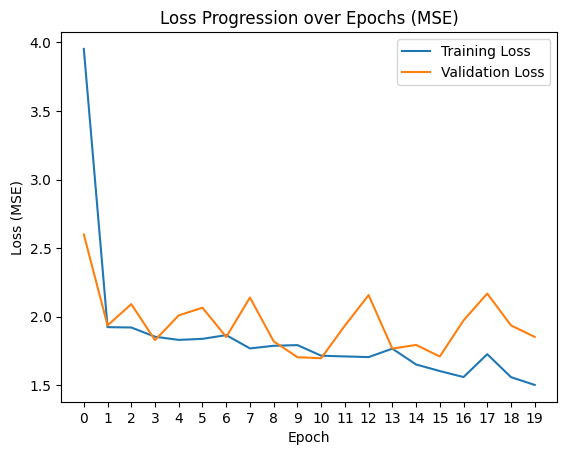

In [ ]:


# Plot the curves
plt.plot(train_losses, label='Training Loss')
plt.plot(val_losses, label='Validation Loss')

plt.xticks(range(0, 20))


plt.xlabel('Epoch')
plt.ylabel('Loss (MSE)')
plt.legend()
plt.title("Loss Progression over Epochs (MSE)")
plt.show()

# MAE

In [ ]:

#ini model and opt.
model = GCN(num_layers=4, hidden_size=128)

example_batch = next(iter(train_loader))

rng = jax.random.PRNGKey(0)
params = model.init(rng, example_batch)

optimizer = optax.adam(1e-4)
opt_state = optimizer.init(params)

#mae loss
def loss_mae(params, batch):
    preds = model.apply(params, batch)
    targets = batch.globals
    loss = jnp.mean(jnp.abs(preds.squeeze() - targets.squeeze()))
    return loss

#step

def train_step(params, opt_state, batch):
    loss, grads = jax.value_and_grad(loss_mae)(params, batch)
    updates, opt_state = optimizer.update(grads, opt_state)
    params = optax.apply_updates(params, updates)
    return params, opt_state, loss



#training ( loop over batches and graphs)
num_epochs = 20
train_losses = []
val_losses = []

for epoch in range(num_epochs):
    #train
    batch_losses = []
    for batch in train_loader:
        params, opt_state, loss = train_step(params, opt_state, batch)
        batch_losses.append(loss)
    train_loss = jnp.mean(jnp.array(batch_losses))

    #val
    val_batch_losses = []
    for batch in val_loader:
        val_loss = loss_mae(params, batch)
        val_batch_losses.append(val_loss)
    val_loss = jnp.mean(jnp.array(val_batch_losses))

    train_losses.append(train_loss)
    val_losses.append(val_loss)

    print(f"Epoch {epoch+1}: Train Loss={train_loss:.4f}, Val Loss={val_loss:.4f}")

Epoch 1: Train Loss=1.5266, Val Loss=1.2797
Epoch 2: Train Loss=1.0780, Val Loss=1.0864
Epoch 3: Train Loss=1.0587, Val Loss=1.0423
Epoch 4: Train Loss=1.0196, Val Loss=1.1275
Epoch 5: Train Loss=1.0206, Val Loss=1.1093
Epoch 6: Train Loss=1.0126, Val Loss=1.0512
Epoch 7: Train Loss=1.0048, Val Loss=1.0905
Epoch 8: Train Loss=0.9973, Val Loss=1.0652
Epoch 9: Train Loss=0.9902, Val Loss=1.0681
Epoch 10: Train Loss=0.9726, Val Loss=1.1631
Epoch 11: Train Loss=0.9987, Val Loss=1.1590
Epoch 12: Train Loss=0.9955, Val Loss=1.0380
Epoch 13: Train Loss=0.9580, Val Loss=0.9980
Epoch 14: Train Loss=0.9530, Val Loss=1.0205
Epoch 15: Train Loss=0.9907, Val Loss=1.1832
Epoch 16: Train Loss=0.9773, Val Loss=0.9819
Epoch 17: Train Loss=0.9354, Val Loss=0.9527
Epoch 18: Train Loss=0.9184, Val Loss=0.9677
Epoch 19: Train Loss=0.8925, Val Loss=1.0838
Epoch 20: Train Loss=0.8883, Val Loss=0.9824


In [ ]:
#eval on test
test_losses = []
for batch in test_loader:
    loss = loss_mae(params, batch)
    test_losses.append(loss)
print(f"Test Loss: {jnp.mean(jnp.array(test_losses)):.4f}")

Test Loss: 0.8835


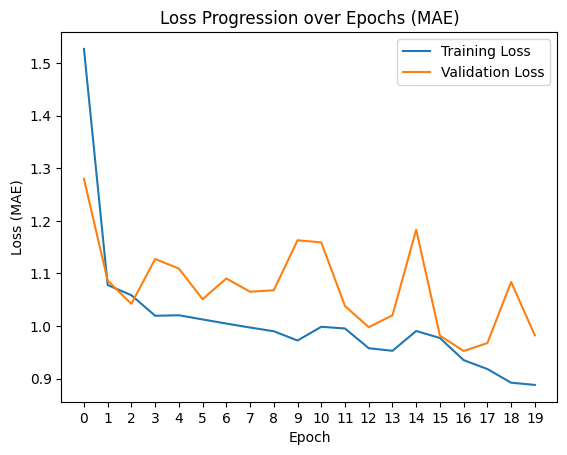

In [ ]:
# Plot the curves
plt.plot(train_losses, label='Training Loss')
plt.plot(val_losses, label='Validation Loss')

plt.xticks(range(0, 20))


plt.xlabel('Epoch')
plt.ylabel('Loss (MAE)')
plt.legend()
plt.title("Loss Progression over Epochs (MAE)")
plt.show()

# Huber

In [ ]:
#ini model and opt.
model = GCN(num_layers=4, hidden_size=128)

example_batch = next(iter(train_loader))

rng = jax.random.PRNGKey(0)
params = model.init(rng, example_batch)

optimizer = optax.adam(1e-4)
opt_state = optimizer.init(params)

#huber loss

def loss_huber(params, batch):
    preds = model.apply(params, batch)
    targets = batch.globals
    return jnp.mean(optax.huber_loss(preds.squeeze(), targets.squeeze()))

#step

def train_step(params, opt_state, batch):
    loss, grads = jax.value_and_grad(loss_huber)(params, batch)
    updates, opt_state = optimizer.update(grads, opt_state)
    params = optax.apply_updates(params, updates)
    return params, opt_state, loss



#training ( loop over batches and graphs)
num_epochs = 20
train_losses = []
val_losses = []

for epoch in range(num_epochs):
    #train
    batch_losses = []
    for batch in train_loader:
        params, opt_state, loss = train_step(params, opt_state, batch)
        batch_losses.append(loss)
    train_loss = jnp.mean(jnp.array(batch_losses))

    #val
    val_batch_losses = []
    for batch in val_loader:
        val_loss = loss_huber(params, batch)
        val_batch_losses.append(val_loss)
    val_loss = jnp.mean(jnp.array(val_batch_losses))

    train_losses.append(train_loss)
    val_losses.append(val_loss)

    print(f"Epoch {epoch+1}: Train Loss={train_loss:.4f}, Val Loss={val_loss:.4f}")

Epoch 1: Train Loss=1.1115, Val Loss=0.8165
Epoch 2: Train Loss=0.6545, Val Loss=0.6501
Epoch 3: Train Loss=0.6604, Val Loss=0.7980
Epoch 4: Train Loss=0.6365, Val Loss=0.6650
Epoch 5: Train Loss=0.6279, Val Loss=0.7176
Epoch 6: Train Loss=0.6232, Val Loss=0.7292
Epoch 7: Train Loss=0.6263, Val Loss=0.7145
Epoch 8: Train Loss=0.6365, Val Loss=0.7741
Epoch 9: Train Loss=0.6157, Val Loss=0.7556
Epoch 10: Train Loss=0.6201, Val Loss=0.7091
Epoch 11: Train Loss=0.5950, Val Loss=0.6756
Epoch 12: Train Loss=0.5965, Val Loss=0.7203
Epoch 13: Train Loss=0.5814, Val Loss=0.6206
Epoch 14: Train Loss=0.5559, Val Loss=0.5888
Epoch 15: Train Loss=0.5477, Val Loss=0.6367
Epoch 16: Train Loss=0.5365, Val Loss=0.5980
Epoch 17: Train Loss=0.5260, Val Loss=0.6480
Epoch 18: Train Loss=0.5047, Val Loss=0.6676
Epoch 19: Train Loss=0.4935, Val Loss=0.5808
Epoch 20: Train Loss=0.4868, Val Loss=0.5638


In [ ]:
#eval on test
test_losses = []
for batch in test_loader:
    loss = loss_huber(params, batch)
    test_losses.append(loss)
print(f"Test Loss: {jnp.mean(jnp.array(test_losses)):.4f}")

Test Loss: 0.4473


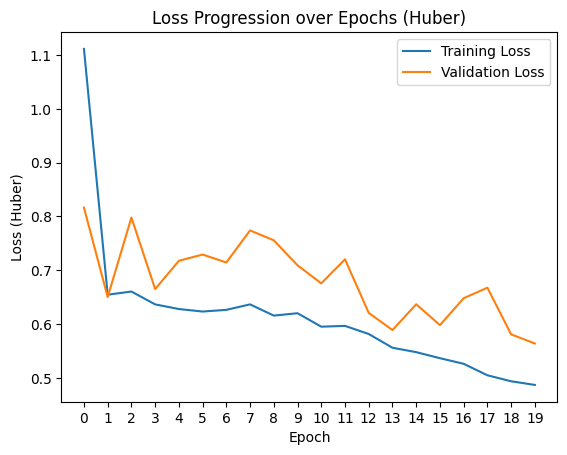

In [ ]:
# Plot the curves
plt.plot(train_losses, label='Training Loss')
plt.plot(val_losses, label='Validation Loss')

plt.xticks(range(0, 20))


plt.xlabel('Epoch')
plt.ylabel('Loss (Huber)')
plt.legend()
plt.title("Loss Progression over Epochs (Huber)")
plt.show()

For this project, we utilize the QM9 dataset, which is readily available through `torch_geometric.datasets.QM9` and does not necessitate manual download. This simplifies the initial data acquisition, as the dataset provides molecular data already structured as graphs. The QM9 dataset comprises approximately 133,000 small organic molecules. Each molecule is represented as a graph where nodes correspond to atoms and edges represent chemical bonds.

Node features (`G.x`) are 11-dimensional vectors for each atom, including information such as one-hot encoded atom type (H, C, N, O, F), atomic number, aromaticity, electron orbital hybridization (sp, sp2, sp3), and the number of attached hydrogens. Edge features (`G.edge_attr`) are 4-dimensional one-hot encoded vectors describing the bond type (single, double, triple, aromatic). The dataset also includes the edge index (`G.edge_index`) representing the graph's connectivity, 3D coordinates for each atom (`G.pos`), and 19 target properties (`G.y`) that describe various chemical characteristics of the molecule. For this project, we specifically focus on one of these 19 regression targets, the electric dipole moment (target index 0), as set by the `SetTarget` transform during data loading (Code cell `DzLRbSgWGz0d`).